In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import numpy as np
import pandas as pd

# ScikitLearn classes
from sklearn.linear_model import Lasso, ElasticNet, Ridge, LinearRegression
# from sklearn.model_selection import cross_val_score
# from sklearn.model_selection import GridSearchCV
# from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

from mpl_toolkits.mplot3d import Axes3D

In [39]:
def griewank(X):
    x1 = X[0]
    x2 = X[1]
    obj = 0.2 + x1**2 + x2**2 - 0.1*np.cos(6.0*3.1415*x1) - 0.1*np.cos(6.0*3.1415*x2)
    return obj

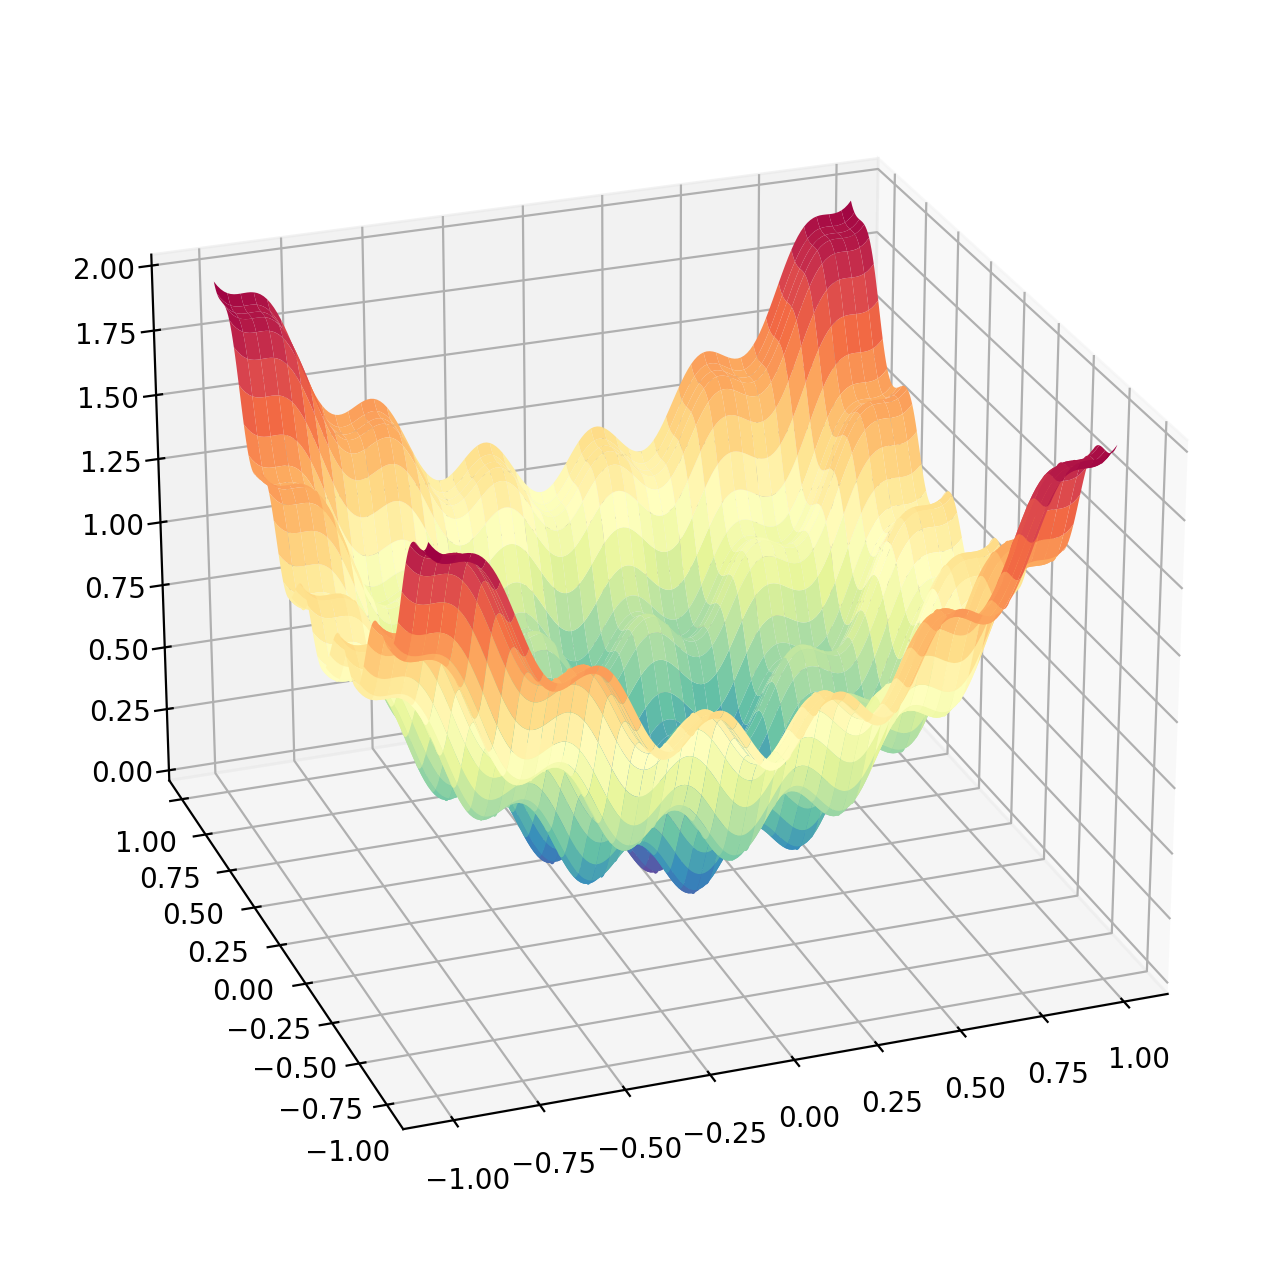

In [4]:
# define range for input
r_min, r_max = -1.0, 1.0
# sample input range uniformly at 0.1 increments
xaxis = np.arange(r_min, r_max, 0.01)
yaxis = np.arange(r_min, r_max, 0.01)
# create a mesh from the axis
X = np.meshgrid(xaxis, yaxis)
# compute targets
results = griewank(X)
# create a surface plot with the jet color scheme
figure = plt.figure(figsize=(10,8))
axis = figure.add_subplot(projection='3d')
axis.plot_surface(X[0], X[1], results, cmap='Spectral_r')
axis.view_init(25,250)
# show the plot
plt.show()

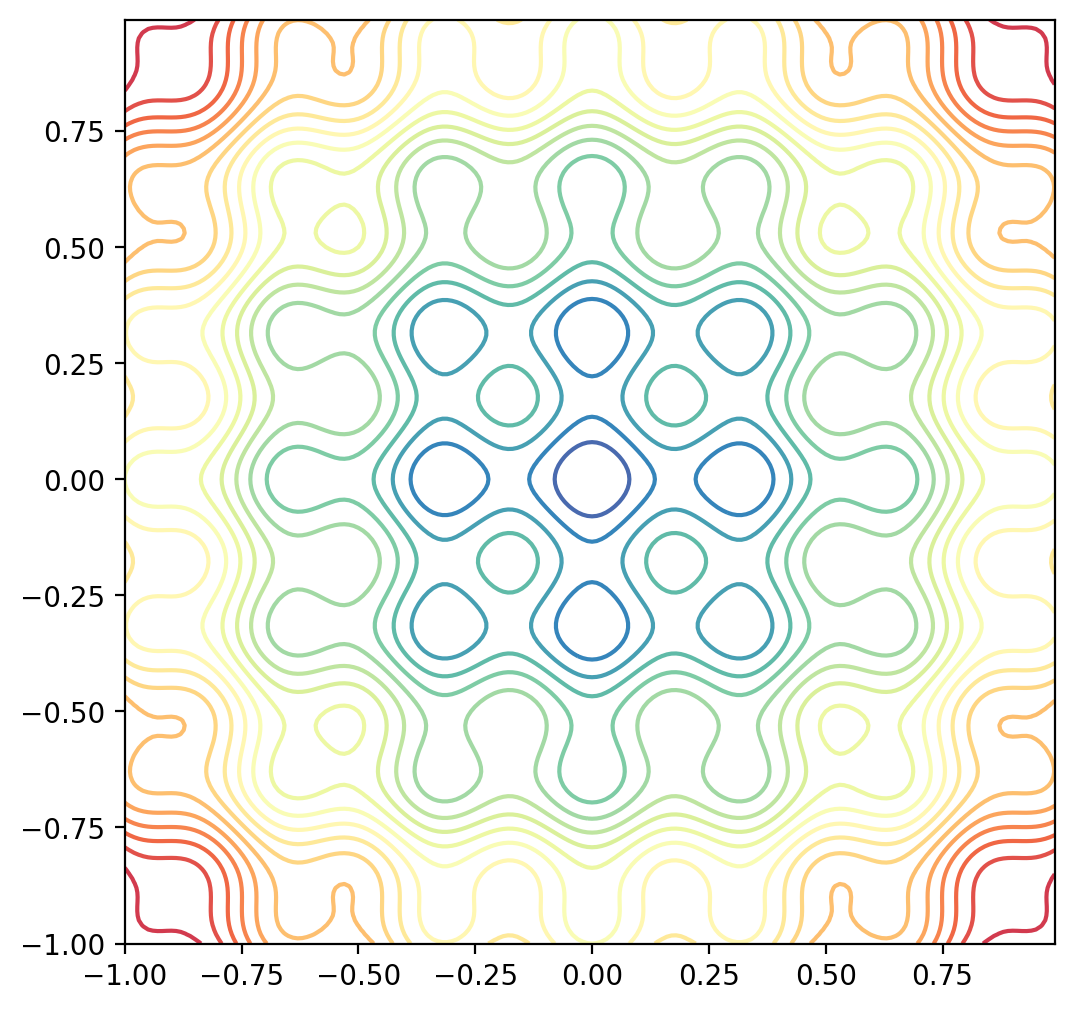

In [5]:
figure = plt.figure(figsize=(6,6))
plt.contour(X[0], X[1], results, 20, alpha=1.0, cmap='Spectral_r')
plt.show()

In [34]:
# Generate a random candidate solution near the current solution for n dimensions
def get_candidate_solution(current_solution, bounds,temp):
    # this is the gaussian step annealing
    return [np.clip(xi + np.random.normal() * (bounds[i][1] - bounds[i][0]) * temp,bounds[i][0],bounds[i][1]) for i, xi in enumerate(current_solution)]

# Simulated Annealing algorithm for n dimensions with different bounds
def simulated_annealing(objective, bounds, max_iterations, initial_temp, cooling_rate):
    dimensions = len(bounds)
    
    # Initialize with a random solution within the specific bounds for each dimension
    current_solution = [np.random.uniform(bounds[i][0], bounds[i][1]) for i in range(dimensions)]
    current_solution_cost = objective(current_solution)

    # define a structure to keep track of your progress
    best_solution = current_solution[:]
    best_solution_cost = current_solution_cost

    # Current temperature
    temp = initial_temp

    for iteration in range(max_iterations):
        # Get a candidate solution respecting individual dimension bounds
        candidate_solution = get_candidate_solution(current_solution, bounds,temp)
        candidate_solution_cost = objective(candidate_solution)

        # Check if the candidate solution is better
        if candidate_solution_cost < current_solution_cost:
            current_solution, current_solution_cost = candidate_solution, candidate_solution_cost
            if candidate_solution_cost < best_solution_cost:
                best_solution, best_solution_cost = candidate_solution, candidate_solution_cost
        else:
            # Accept worse solutions with a certain probability
            # for exploration
            if np.random.uniform(0, 1) < np.exp((current_solution_cost - candidate_solution_cost) / temp):
                current_solution, current_solution_cost = candidate_solution, candidate_solution_cost

        # Decrease the temperature
        temp *= cooling_rate

        # Optional: Output some information
        if (iteration+1) % 500 == 0:
            print(f"Iteration {iteration+1}, Temperature: {temp:.2f}, Current Solution: {current_solution}, Current Cost: {current_solution_cost}")

    return best_solution, best_solution_cost




In [7]:
bounds = [(-1,1),(-1,1)]
maxsteps = 3000
initial_temp = 1
cooling_rate = 0.99

In [8]:
simulated_annealing(griewank,bounds,maxsteps,initial_temp,cooling_rate)

Iteration 500, Temperature: 0.01, Current Solution: [np.float64(0.0045372218481791364), np.float64(0.01774991391020655)], Current Cost: 0.006245903619079909
Iteration 1000, Temperature: 0.00, Current Solution: [np.float64(-0.0011632353117472087), np.float64(0.0012464147255711892)], Current Cost: 5.453914735691068e-05
Iteration 1500, Temperature: 0.00, Current Solution: [np.float64(-0.0005809351631054823), np.float64(0.0007948510212333653)], Current Cost: 1.8187416602338802e-05
Iteration 2000, Temperature: 0.00, Current Solution: [np.float64(-0.0005872062408152242), np.float64(0.0007992572106219124)], Current Cost: 1.845666577218741e-05
Iteration 2500, Temperature: 0.00, Current Solution: [np.float64(-0.0005872654544486902), np.float64(0.0007992712615457553)], Current Cost: 1.8458392145856428e-05
Iteration 3000, Temperature: 0.00, Current Solution: [np.float64(-0.0005872653841848862), np.float64(0.0007992712163348078)], Current Cost: 1.8458389241277073e-05


([np.float64(-0.00022540867542634319), np.float64(3.876504717070904e-05)],
 np.float64(9.81589810697403e-07))

## PSO Application

In [40]:
# PSO algorithm

def pso(objective, num_dimensions, num_particles, max_iter,i_min=-10,i_max=10,bounds=None,w=0.5,c1=0.3,c2=0.6):
    # Initialize the particles
    # This creates a data structure such as a dictionary
    # very important: initiate a tracker variables
    if bounds is None:
        particles = [({'position': [np.random.uniform(i_min, i_max) for _ in range(num_dimensions)],
                    'velocity': [np.random.uniform(-1, 1) for _ in range(num_dimensions)],
                    'pbest': float('inf'),
                    'pbest_position': None})
                    for _ in range(num_particles)]
    else:
        particles = [({'position': [np.random.uniform(bounds[i][0], bounds[i][1]) for i in range(num_dimensions)],
                    'velocity': [np.random.uniform(-1, 1) for _ in range(num_dimensions)],
                    'pbest': float('inf'),
                    'pbest_position': None})
                    for _ in range(num_particles)]

    # Initialize global best
    gbest_value = float('inf')
    gbest_position = None

    for _ in range(max_iter):
        for particle in particles:
            position = particle['position']
            velocity = particle['velocity']

            # Calculate the current value
            current_value = objective(position)

            # Update personal best
            # because you see "<" it means the code minimizes the objective
            if current_value < particle['pbest']:
                particle['pbest'] = current_value
                particle['pbest_position'] = position.copy()

            # Update global best
            if current_value < gbest_value:
                gbest_value = current_value
                gbest_position = position.copy()

            # Update particle's velocity and position
            for i in range(num_dimensions):
                r1, r2 = np.random.uniform(), np.random.uniform()
                # here below we have the equation from the slides
                velocity[i] = w * velocity[i] + c1*r1 * (particle['pbest_position'][i] - position[i]) + c2*r2 * (gbest_position[i] - position[i])
                position[i] += velocity[i]
                # legalize the values to the provided bounds
                if bounds is not None:
                    position[i] = np.clip(position[i],bounds[i][0],bounds[i][1])

    return gbest_position, gbest_value

In [41]:
ndim = 2
nparticles = 20
max_iter = 200
bounds= [(-1,1),(-1,1)]

In [43]:
pso(griewank,ndim,nparticles,max_iter,bounds=bounds,w=0.5,c1=0.3,c2=0.4)

([np.float64(-4.4649022788316206e-10), np.float64(1.8085796779846814e-10)],
 np.float64(0.0))

## Real Data Application for Tuning ElasticNet

In [44]:
data = pd.read_csv('concrete.csv',sep='\t')

In [45]:
data

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,322.0,0.0,0.0,203.0,0.0,974.0,800.0,14,20.77
1,322.0,0.0,0.0,203.0,0.0,974.0,800.0,28,25.18
2,322.0,0.0,0.0,203.0,0.0,974.0,800.0,180,29.59
3,302.0,0.0,0.0,203.0,0.0,974.0,817.0,28,21.75
4,397.0,0.0,0.0,185.0,0.0,1040.0,734.0,28,39.09
...,...,...,...,...,...,...,...,...,...
204,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
205,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
206,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
207,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [46]:
x = data.drop(columns='strength').values
y = data['strength'].values
scale  = StandardScaler()

In [47]:
# define the objective function
# the idea here is a mapping between a set of hyperparameters and a k-fold cross-validated MSE

def objective(h):

    K = 5
    
    model = ElasticNet(alpha=h[0],l1_ratio=h[1],max_iter=50000)

    if h[0] == 0:
        model = LinearRegression()

    if h[1] == 0:
        model = Ridge(alpha=h[0])

    if h[1] == 1:
        model = Lasso(alpha=h[0],max_iter=50000)

    indices = np.random.permutation(range(len(x)))
    folds = np.array_split(indices,K)
    mse = []
    
    for fold in folds:
        
        idxtest = fold
        idxtrain = np.delete(range(len(x)),fold)
        
        xtrain = scale.fit_transform(x[idxtrain])
        xtest = scale.transform(x[idxtest])

        ytrain = y[idxtrain]
        ytest = y[idxtest]

        model.fit(xtrain,ytrain)
        mse.append(np.mean((ytest-model.predict(xtest))**2))

    return np.mean(mse)
        

In [48]:
objective([0.2,0.3])

np.float64(142.93130290177567)

In [35]:
bounds = [(0.001,10),(0,1)]
maxsteps = 2000
initial_temp = 10
cooling_temp = 0.99

In [36]:
simulated_annealing(objective,bounds, maxsteps,initial_temp,cooling_temp)

Iteration 500, Temperature: 0.07, Current Solution: [np.float64(0.3659977962801198), np.float64(0.3310578838722316)], Current Cost: 45.71735732798996
Iteration 1000, Temperature: 0.00, Current Solution: [np.float64(0.3416846551763349), np.float64(0.3317696672190204)], Current Cost: 40.721799147314556
Iteration 1500, Temperature: 0.00, Current Solution: [np.float64(0.3418355428307438), np.float64(0.33200432152316695)], Current Cost: 39.18756458795246
Iteration 2000, Temperature: 0.00, Current Solution: [np.float64(0.3418355428307438), np.float64(0.33200432152316695)], Current Cost: 39.18756458795246


([np.float64(0.3418355428307438), np.float64(0.33200432152316695)],
 np.float64(39.18756458795246))

In [63]:
ndim = 2
nparticles = 40
max_iter = 200
bounds= [(0.001,10),(0,1)]

In [64]:
pso(objective,ndim,nparticles,max_iter,bounds=bounds,w=0.5,c1=0.3,c2=0.4)

([np.float64(0.9723640429981736), np.float64(0.9992590884727937)],
 np.float64(36.85189180951826))

In [65]:
alpha = 0.2
l1_ratio = 0.5
scale = StandardScaler()
model = ElasticNet(alpha=alpha,l1_ratio=l1_ratio)

In [66]:
from sklearn.pipeline import Pipeline

In [ ]:
pipe = Pipeline([['Scaler',scale],